# THÀNH VIÊN 1: DATA PIPELINE & KHÁM PHÁ DỮ LIỆU (EDA & STYLIZED FACTS)
## Phần 1 – Làm sạch dữ liệu (Data Cleaning)
1. Xử lý giá đóng cửa điều chỉnh (Adjusted Close)
2. Xử lý ngày nghỉ lễ, Tết và ngày không giao dịch
3. Căn chỉnh lịch giao dịch giữa các cổ phiếu (Calendar Alignment)

**Cấu trúc thư mục:** `Project midterm/` gồm `Input/` (file .xlsx), `Output/` (kết quả), `Code/` (notebook này).

In [1]:
import os
import re
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# ===================== CẤU HÌNH =====================
def find_base_dir() -> Path:
    """Ưu tiên: biến môi trường PROJECT_DIR -> đường dẫn mặc định -> thư mục cha của Code/."""
    env = os.environ.get("PROJECT_DIR")
    if env:
        return Path(env)
    default = Path(r"D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm")
    if default.exists():
        return default
    cwd = Path.cwd()
    return cwd.parent if cwd.name.lower() == "code" else cwd


BASE_DIR = find_base_dir()
INPUT_DIR = BASE_DIR / "Input"
# chấp nhận cả tên thư mục viết sai "Ouput" nếu bạn đã lỡ tạo như vậy
OUTPUT_DIR = next((BASE_DIR / n for n in ("Output", "Ouput") if (BASE_DIR / n).exists()),
                  BASE_DIR / "Output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED_COLS = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
FFILL_LIMIT = 10          # tối đa số phiên liên tiếp được điền giá (cổ phiếu tạm ngừng GD)
GAP_THRESHOLD_DAYS = 4    # khoảng cách giữa 2 phiên > 4 ngày lịch => ghi nhận kỳ nghỉ dài
SUSPICIOUS_RET = 0.15     # |r| > 15%/ngày => nghi ngờ lỗi dữ liệu / chưa điều chỉnh chia tách
COMMON_SAMPLE = True      # True: chỉ giữ giai đoạn mà TẤT CẢ cổ phiếu cùng có dữ liệu
START_DATE = None         # vd "2022-01-01" để ép mốc bắt đầu (None = tự động)
END_DATE = None           # vd "2024-12-31" để ép mốc kết thúc (None = tự động)

EVENTS = {}               # sự kiện cổ tức / chia tách tách ra từ file Yahoo
PRICE_LIMIT = 0.07        # biên độ giá ngày HOSE (±7%) để cảnh báo dữ liệu bất thường
REPORT = []               # nhật ký xử lý -> ghi ra Output/cleaning_report.txt


def log(msg=""):
    print(msg)
    REPORT.append(str(msg))


print("BASE_DIR  :", BASE_DIR)
print("INPUT_DIR :", INPUT_DIR, "| tồn tại:", INPUT_DIR.exists())
print("OUTPUT_DIR:", OUTPUT_DIR)

BASE_DIR  : D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm
INPUT_DIR : D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm\Input | tồn tại: True
OUTPUT_DIR: D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm\Output


In [3]:
# ===================== 1. ĐỌC DỮ LIỆU =====================
def _map_col(col):
    """Chuẩn hoá tên cột (tiêu đề có thể kèm mô tả như 'Close price adjusted for splits.')."""
    c = str(col).strip().lower()
    for key, name in [("adj", "Adj Close"), ("date", "Date"), ("open", "Open"),
                      ("high", "High"), ("low", "Low"), ("close", "Close"),
                      ("volume", "Volume")]:
        if c.startswith(key):
            return name
    return col


def _parse_dates_once(s: pd.Series, swap: bool) -> pd.Series:
    """Parse cột ngày hỗn hợp (datetime thật + chuỗi dd/mm/yyyy).
    swap=True: đảo ngày<->tháng cho các ô đã bị Excel tự đổi thành datetime (lỗi locale)."""
    out = []
    for v in s:
        if pd.isna(v):
            out.append(pd.NaT)
        elif isinstance(v, (pd.Timestamp, dt.datetime, dt.date)):
            ts = pd.Timestamp(v)
            if swap and ts.day <= 12:
                ts = pd.Timestamp(year=ts.year, month=ts.day, day=ts.month)
            out.append(ts)
        else:
            txt = str(v).strip()
            iso = re.match(r"^\d{4}-\d{2}-\d{2}", txt) is not None
            out.append(pd.to_datetime(txt, dayfirst=not iso, errors="coerce"))
    return pd.Series(pd.to_datetime(out), index=s.index)


def _order_violations(d: pd.Series) -> int:
    """Số lần vi phạm thứ tự thời gian (dữ liệu gốc phải tăng dần HOẶC giảm dần)."""
    diff = d.dropna().diff().dropna()
    return int(min((diff < pd.Timedelta(0)).sum(), (diff > pd.Timedelta(0)).sum()))


def parse_dates(s: pd.Series, name: str) -> pd.Series:
    """Thử 2 cách đọc ngày, chọn cách cho chuỗi đúng thứ tự thời gian & ít trùng ngày nhất."""
    has_dt = any(isinstance(v, (pd.Timestamp, dt.datetime, dt.date)) for v in s)
    cands = {False: _parse_dates_once(s, False)}
    if has_dt:
        cands[True] = _parse_dates_once(s, True)
    score = {k: _order_violations(v) + int(v.dropna().duplicated().sum()) for k, v in cands.items()}
    best = min(score, key=score.get)
    if has_dt:
        log(f"  - {name}: điểm lỗi ngày (thứ tự+trùng): không đảo={score[False]}, "
            f"đảo ngày/tháng={score[True]} -> chọn {'ĐẢO' if best else 'KHÔNG đảo'}")
    return cands[best]


def _to_number(s: pd.Series) -> pd.Series:
    """Đọc số an toàn: hỗ trợ '1,234.56' (kiểu Mỹ), '1.234,56' (kiểu Việt), khoảng trắng, '#N/A', '-'."""
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_numeric(s, errors="coerce")

    def conv(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v)
        t = str(v).strip().replace("\u00a0", "").replace(" ", "").replace("%", "")
        if t in ("", "-", "--", "#N/A", "N/A", "NA", "nan", "None", "#VALUE!", "#REF!", "#DIV/0!"):
            return np.nan
        if "," in t and "." in t:                      # dấu cuối cùng là dấu thập phân
            if t.rfind(",") > t.rfind("."):
                t = t.replace(".", "").replace(",", ".")
            else:
                t = t.replace(",", "")
        elif "," in t:
            if re.fullmatch(r"-?\d{1,3}(,\d{3})+", t):  # 1,234 hoặc 1,234,567 -> phân nhóm nghìn
                t = t.replace(",", "")
            else:                                      # 12,5 -> thập phân
                t = t.replace(",", ".")
        elif t.count(".") > 1:                         # 1.234.567 -> phân nhóm nghìn
            t = t.replace(".", "")
        try:
            return float(t)
        except ValueError:
            return np.nan

    return s.map(conv).astype(float)


def load_stock(path: Path) -> pd.DataFrame:
    """Đọc 1 file Excel -> DataFrame index = Date, các cột số chuẩn hoá."""
    df = pd.read_excel(path, sheet_name=0)
    orig_cols = list(df.columns)
    df.columns = [_map_col(c) for c in df.columns]

    dup_cols = [c for c in df.columns[df.columns.duplicated()].unique()]
    if dup_cols:
        raise ValueError(f"{path.name}: nhiều cột cùng được map thành {dup_cols}. "
                         f"Tiêu đề gốc: {orig_cols}")
    missing = [c for c in ["Date"] + REQUIRED_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"{path.name}: thiếu cột {missing}. Tiêu đề gốc: {orig_cols}")

    df = df[["Date"] + REQUIRED_COLS].copy()
    raw_vals = df[REQUIRED_COLS].copy()                 # giữ bản gốc để chẩn đoán
    df["Date"] = parse_dates(df["Date"], path.stem.upper())
    tk_name = path.stem.upper()

    # --- Tách dòng sự kiện (Dividend / Stock Splits) mà Yahoo chen vào bảng giá ---
    is_event = raw_vals.apply(
        lambda col: col.astype(str).str.contains(r"dividend|stock\s*split", case=False,
                                                 regex=True, na=False)).any(axis=1)
    if is_event.any():
        ev = df.loc[is_event, ["Date"]].copy()
        m = raw_vals.loc[is_event, "Open"].astype(str).str.extract(
            r"^\s*([\d.,:]+)\s*(Dividend|Stock\s*Splits?)", flags=re.I)
        ev["Ticker"] = tk_name
        ev["Type"] = m[1].str.title()
        ev["Value"] = m[0]
        EVENTS[tk_name] = ev.drop_duplicates().reset_index(drop=True)
        n_div = int((ev["Type"] == "Dividend").sum()); n_spl = int(len(ev) - n_div)
        log(f"      ℹ {tk_name}: tách {int(is_event.sum())} dòng sự kiện khỏi dữ liệu giá "
            f"({n_div} cổ tức, {n_spl} chia tách/cổ phiếu thưởng)")
        df = df.loc[~is_event].copy()
        raw_vals = raw_vals.loc[~is_event]

    for c in REQUIRED_COLS:
        df[c] = _to_number(df[c])

    # Chẩn đoán: cột nào không đọc được thành số
    for c in ["Close", "Adj Close"]:
        n_ok = int(df[c].notna().sum())
        if n_ok == 0:
            sample = raw_vals[c].dropna().astype(str).head(5).tolist()
            raise ValueError(
                f"{path.name}: cột '{c}' KHÔNG đọc được giá trị số nào "
                f"(tiêu đề gốc: {orig_cols}). Ví dụ giá trị gốc: {sample}")
        if n_ok < 0.95 * len(df):
            bad = raw_vals.loc[df[c].isna(), c].dropna().astype(str).unique()[:5].tolist()
            log(f"      ⚠ {path.stem.upper()}: cột '{c}' chỉ đọc được {n_ok}/{len(df)} ô. "
                f"Ví dụ ô lỗi: {bad}")

    n_bad_date = int(df["Date"].isna().sum())
    df = df.dropna(subset=["Date"])
    df["Date"] = df["Date"].dt.normalize()

    dup_mask = df["Date"].duplicated(keep=False)
    n_dup = int(df["Date"].duplicated().sum())
    if n_dup:
        d = df[dup_mask].sort_values("Date")
        same = int(d.groupby("Date")[REQUIRED_COLS].nunique(dropna=False).max(axis=1).eq(1).sum())
        ex = ", ".join(x.strftime("%Y-%m-%d") for x in d["Date"].drop_duplicates().head(6))
        log(f"      ℹ {path.stem.upper()}: {n_dup} dòng trùng ngày "
            f"({same}/{d['Date'].nunique()} ngày trùng có giá trị GIỐNG HỆT) | ví dụ: {ex}")
    df = df.drop_duplicates(subset="Date", keep="last").sort_values("Date").set_index("Date")

    log(f"  - Đọc {path.name}: {len(df)} dòng | {df.index.min().date()} -> {df.index.max().date()}"
        f" | ngày lỗi bỏ: {n_bad_date} | ngày trùng bỏ: {n_dup}")
    return df


def load_all() -> dict:
    files = sorted(p for p in INPUT_DIR.glob("*.xlsx") if not p.name.startswith("~$"))
    if not files:
        raise FileNotFoundError(f"Không tìm thấy file .xlsx trong {INPUT_DIR}")
    log("=" * 78)
    log("ĐỌC DỮ LIỆU")
    log("=" * 78)
    return {p.stem.upper(): load_stock(p) for p in files}

In [4]:
# ===================== BƯỚC 1 – GIÁ ĐÓNG CỬA ĐIỀU CHỈNH =====================
def step1_adjusted_prices(data: dict) -> dict:
    """
    - Hệ số điều chỉnh Adj_Factor = Adj Close / Close (chia tách + cổ tức).
    - Điều chỉnh Open/High/Low theo cùng hệ số -> Adj_Open / Adj_High / Adj_Low.
    - Kiểm tra: giá <= 0, High < Low, ngày có sự kiện doanh nghiệp, biến động bất thường.
    - Mọi phân tích lợi suất về sau dùng Adj Close (KHÔNG dùng Close).
    """
    log("")
    log("=" * 78)
    log("BƯỚC 1: XỬ LÝ GIÁ ĐÓNG CỬA ĐIỀU CHỈNH (ADJUSTED CLOSE)")
    log("=" * 78)
    out = {}
    for tk, df in data.items():
        df = df.copy()

        # Giá <= 0 là không hợp lệ -> NaN (ngày Volume=0 có thể có giá 0)
        for c in ["Open", "High", "Low", "Close", "Adj Close"]:
            df.loc[df[c] <= 0, c] = np.nan

        df["Adj_Factor"] = df["Adj Close"] / df["Close"]
        if df["Adj_Factor"].notna().sum() == 0:
            raise ValueError(f"[{tk}] Adj_Factor toàn NaN: Close và Adj Close không có dòng nào cùng hợp lệ")
        for c in ["Open", "High", "Low"]:
            df[f"Adj_{c}"] = df[c] * df["Adj_Factor"]

        # Ngày hệ số điều chỉnh đổi => có cổ tức / chia tách / phát hành thêm
        n_events = int((df["Adj_Factor"].pct_change().abs() > 1e-4).sum())

        r_close = df["Close"].pct_change()
        r_adj = df["Adj Close"].pct_change()
        n_diff = int(((r_close - r_adj).abs() > 1e-4).sum())
        suspicious = r_adj.index[r_adj.abs() > SUSPICIOUS_RET]
        bad_hl = int((df["High"] < df["Low"]).sum())

        log(f"  [{tk}] Adj_Factor: min={df['Adj_Factor'].min():.4f}, max={df['Adj_Factor'].max():.4f} "
            f"| ngày hệ số đổi: {n_events} | ngày r(Close)≠r(Adj Close): {n_diff} | High<Low: {bad_hl}")
        if len(suspicious):
            ds = ", ".join(d.strftime("%Y-%m-%d") for d in suspicious[:8])
            log(f"      ⚠ {len(suspicious)} ngày |r_adj| > {SUSPICIOUS_RET:.0%} (cần kiểm tra): {ds}")
        out[tk] = df
    return out

In [5]:
# ===================== BƯỚC 2 – NGÀY NGHỈ LỄ, TẾT, KHÔNG GIAO DỊCH =====================
def step2_non_trading_days(data: dict) -> dict:
    """
    - Loại dòng Thứ 7/CN, loại dòng thiếu Adj Close.
    - Is_Traded = (Volume > 0). File tải về thường vẫn có dòng cho ngày lễ với Volume = 0
      -> các dòng này KHÔNG phải phiên giao dịch thật, được gắn cờ để bước 3 loại ra khỏi lịch.
    - Thống kê các kỳ nghỉ dài (Tết, 30/4–1/5, 2/9...) dựa trên các PHIÊN THẬT.
    """
    log("")
    log("=" * 78)
    log("BƯỚC 2: XỬ LÝ NGÀY NGHỈ LỄ, TẾT & NGÀY KHÔNG GIAO DỊCH")
    log("=" * 78)
    out = {}
    for tk, df in data.items():
        df = df.copy()

        wk = df.index.dayofweek >= 5
        n_wk = int(wk.sum())
        df = df[~wk]

        n_nan = int(df["Adj Close"].isna().sum())
        df = df.dropna(subset=["Adj Close"])
        if df.empty:
            raise ValueError(f"[{tk}] không còn dòng nào sau khi bỏ dòng thiếu Adj Close")

        df["Volume"] = df["Volume"].fillna(0)
        df["Is_Traded"] = df["Volume"] > 0
        n_zero_vol = int((~df["Is_Traded"]).sum())

        real = df.index[df["Is_Traded"]].to_series()
        gaps = real.diff().dt.days
        long_gaps = gaps[gaps > GAP_THRESHOLD_DAYS]

        log(f"  [{tk}] bỏ dòng cuối tuần: {n_wk} | bỏ dòng thiếu Adj Close: {n_nan} "
            f"| dòng Volume=0 (không GD): {n_zero_vol} | kỳ nghỉ dài (>{GAP_THRESHOLD_DAYS} ngày): {len(long_gaps)}")
        for d, g in long_gaps.head(6).items():
            log(f"      nghỉ {int(g)} ngày: {(d - pd.Timedelta(days=int(g))).date()} -> {d.date()}")
        out[tk] = df
    return out

In [6]:
# ===================== BƯỚC 3 – CĂN CHỈNH LỊCH GIAO DỊCH =====================
def step3_calendar_alignment(data: dict):
    """
    - Lịch chuẩn (master calendar) = các ngày làm việc mà ÍT NHẤT 1 mã có giao dịch thật
      (Volume > 0). Ngày không mã nào giao dịch = nghỉ lễ/Tết của thị trường -> loại khỏi lịch.
    - Cắt về giai đoạn chung nếu COMMON_SAMPLE=True (hoặc theo START_DATE/END_DATE).
    - Reindex từng mã theo lịch chuẩn:
        + Giá: forward-fill (tối đa FFILL_LIMIT phiên), cờ Is_Traded = False.
        + Volume: điền 0.
    - Tạo panel dạng rộng: AdjClose, LogReturn, SimpleReturn, Volume, Is_Traded.
    """
    log("")
    log("=" * 78)
    log("BƯỚC 3: CĂN CHỈNH LỊCH GIAO DỊCH GIỮA CÁC CỔ PHIẾU")
    log("=" * 78)

    empty = [tk for tk, df in data.items() if df.empty]
    if empty:
        raise ValueError(f"Các mã không có dữ liệu hợp lệ: {empty}")

    log("  Phạm vi dữ liệu từng mã:")
    for tk, df in data.items():
        log(f"     {tk}: {df.index.min().date()} -> {df.index.max().date()} ({len(df)} dòng)")

    start = max(df.index.min() for df in data.values()) if COMMON_SAMPLE else \
        min(df.index.min() for df in data.values())
    end = min(df.index.max() for df in data.values()) if COMMON_SAMPLE else \
        max(df.index.max() for df in data.values())
    if START_DATE:
        start = pd.Timestamp(START_DATE)
    if END_DATE:
        end = pd.Timestamp(END_DATE)
    log(f"  Giai đoạn phân tích: {start.date()} -> {end.date()}")

    # Phiên thật = ngày có ít nhất 1 mã Volume > 0
    traded_days = sorted(set().union(*[set(df.index[df["Is_Traded"]]) for df in data.values()]))
    master = pd.DatetimeIndex(traded_days)
    master = master[(master >= start) & (master <= end)]
    if len(master) == 0:
        raise ValueError(f"Lịch chuẩn rỗng trong khoảng {start.date()} -> {end.date()}. "
                         "Kiểm tra START_DATE/END_DATE hoặc giai đoạn của các file.")
    log(f"  Số phiên trong lịch chuẩn: {len(master)}")

    all_bdays = pd.bdate_range(master.min(), master.max())
    holidays = all_bdays.difference(master)
    log(f"  Số ngày làm việc (T2–T6) nghỉ lễ/Tết, không mã nào giao dịch: {len(holidays)}")

    aligned = {}
    price_cols = ["Open", "High", "Low", "Close", "Adj Close",
                  "Adj_Open", "Adj_High", "Adj_Low", "Adj_Factor"]
    for tk, df in data.items():
        n_real = int(df.loc[df.index.isin(master), "Is_Traded"].sum())
        a = df.reindex(master)
        a.index.name = "Date"

        a["Is_Traded"] = a["Is_Traded"].fillna(False).astype(bool)
        a["Volume"] = a["Volume"].fillna(0)
        a[price_cols] = a[price_cols].ffill(limit=FFILL_LIMIT)

        n_left_nan = int(a["Adj Close"].isna().sum())
        log(f"  [{tk}] phiên GD thật {n_real}/{len(master)} | phiên điền giá (không GD): "
            f"{int((~a['Is_Traded']).sum())} | NaN còn lại: {n_left_nan}")
        aligned[tk] = a

    adj_close = pd.DataFrame({tk: a["Adj Close"] for tk, a in aligned.items()})
    # Panel cân bằng: bỏ các ngày còn NaN ở bất kỳ mã nào
    n_before = len(adj_close)
    ok = adj_close.notna().all(axis=1)
    adj_close = adj_close[ok]
    if n_before - len(adj_close):
        log(f"  ⚠ Bỏ {n_before - len(adj_close)} ngày còn NaN ở ít nhất 1 mã (panel cân bằng)")
    for tk in aligned:
        aligned[tk] = aligned[tk].loc[adj_close.index]

    volume = pd.DataFrame({tk: a["Volume"] for tk, a in aligned.items()})
    traded = pd.DataFrame({tk: a["Is_Traded"] for tk, a in aligned.items()})
    panels = {
        "AdjClose": adj_close,
        "LogReturn": np.log(adj_close).diff().iloc[1:],
        "SimpleReturn": adj_close.pct_change().iloc[1:],
        "Volume": volume,
        "Is_Traded": traded,
    }
    return aligned, panels, adj_close.index, holidays

In [7]:
# ===================== KIỂM TRA CUỐI =====================
def final_checks(panels):
    log("")
    log("=" * 78)
    log("KIỂM TRA CUỐI")
    log("=" * 78)
    ret = panels["LogReturn"]
    log(f"  Kích thước panel lợi suất: {ret.shape[0]} ngày x {ret.shape[1]} mã")
    log(f"  Tổng số NaN trong panel lợi suất: {int(ret.isna().sum().sum())}")
    log(f"  Tỷ lệ ngày lợi suất = 0 (do không GD/điền giá):")
    for tk, v in (ret == 0).mean().items():
        log(f"     {tk}: {v:.2%}")
    big = (ret.abs() > SUSPICIOUS_RET).sum()
    log(f"  Số ngày |log-return| > {SUSPICIOUS_RET:.0%}: " + ", ".join(f"{k}={v}" for k, v in big.items()))
    sr = panels["SimpleReturn"]
    over = (sr.abs() > PRICE_LIMIT + 0.005).sum()
    log(f"  Số ngày |lợi suất| > biên độ ±{PRICE_LIMIT:.0%} (+0,5% dung sai): "
        + ", ".join(f"{k}={v}" for k, v in over.items()))
    if over.sum():
        st = sr.stack()
        st = st[st.abs() > PRICE_LIMIT + 0.005]
        log("  Các ngày cần kiểm tra:")
        log(st.round(4).to_string())
    log("\n  Thống kê mô tả log-return:")
    log(ret.describe().T[["count", "mean", "std", "min", "max"]].round(5).to_string())

In [8]:
# ===================== CHẨN ĐOÁN NGÀY LỢI SUẤT BẤT THƯỜNG =====================
def diagnose_outliers(aligned, panels, limit=None):
    """Với mỗi ngày |lợi suất| vượt biên độ giá, cho biết nguyên nhân có khả năng nhất:
       - thiếu phiên liền trước (Gap_days > 4)          -> lợi suất nhiều ngày dồn vào 1 ngày
       - gần ngày chia tách/cổ tức (±3 ngày)           -> nghi Yahoo điều chỉnh lệch ngày
       - hệ số điều chỉnh đổi đúng ngày đó               -> nghi điều chỉnh sai
       - còn lại                                         -> có thể là biến động thật / ngoại lệ biên độ
    R_prev / R_next ngược dấu và cùng độ lớn => dấu hiệu lệch ngày (spike rồi đảo chiều)."""
    limit = (PRICE_LIMIT + 0.005) if limit is None else limit
    sr = panels["SimpleReturn"]
    rows = []
    for tk in sr.columns:
        a = aligned[tk]
        r_adj = a["Adj Close"].pct_change()
        r_close = a["Close"].pct_change()
        f_chg = a["Adj_Factor"].pct_change()
        traded_idx = a.index[a["Is_Traded"]]
        ev = EVENTS.get(tk)
        for d in sr.index[sr[tk].abs() > limit]:
            pos = a.index.get_loc(d)
            prev_t = traded_idx[traded_idx < d]
            gap = (d - prev_t[-1]).days if len(prev_t) else np.nan
            near = ""
            if ev is not None and len(ev):
                m = ev[(ev["Date"] - d).dt.days.abs() <= 3]
                near = "; ".join(f"{r.Type} {r.Value} ({r.Date.date()})" for r in m.itertuples())
            if gap == gap and gap > GAP_THRESHOLD_DAYS:
                why = "thiếu phiên liền trước"
            elif near:
                why = "gần ngày sự kiện (nghi điều chỉnh lệch ngày)"
            elif abs(f_chg.iloc[pos]) > 1e-4:
                why = "hệ số điều chỉnh đổi"
            else:
                why = "không rõ / có thể biến động thật"
            rows.append(dict(
                Date=d.date(), Ticker=tk, R_adj=round(r_adj.iloc[pos], 4),
                R_close=round(r_close.iloc[pos], 4),
                R_prev=round(r_adj.iloc[pos - 1], 4) if pos > 0 else np.nan,
                R_next=round(r_adj.iloc[pos + 1], 4) if pos + 1 < len(a) else np.nan,
                Factor_chg=round(f_chg.iloc[pos], 4), Gap_days=gap,
                Traded=bool(a["Is_Traded"].iloc[pos]), Volume=int(a["Volume"].iloc[pos]),
                Near_event=near, Nghi_van=why))
    out = pd.DataFrame(rows)
    log("")
    log("=" * 78)
    log(f"CHẨN ĐOÁN NGÀY |LỢI SUẤT| > {limit:.1%}")
    log("=" * 78)
    if out.empty:
        log("  Không có ngày nào vượt biên độ.")
    else:
        log(out.to_string(index=False))
        log("\n  Tổng hợp nguyên nhân:\n" + out["Nghi_van"].value_counts().to_string())
        out.to_csv(OUTPUT_DIR / "outliers_check.csv", index=False, encoding="utf-8-sig")
    return out

In [9]:
# ===================== LƯU KẾT QUẢ =====================
def save_outputs(aligned, panels, holidays):
    per_dir = OUTPUT_DIR / "clean_by_ticker"
    per_dir.mkdir(exist_ok=True)
    for tk, a in aligned.items():                       # (a) từng mã
        a.to_csv(per_dir / f"{tk}_clean.csv", encoding="utf-8-sig")

    for name, p in panels.items():                      # (b) panel dạng rộng
        p.index.name = "Date"
        p.to_csv(OUTPUT_DIR / f"panel_{name}.csv", encoding="utf-8-sig")

    long = pd.concat([a.assign(Ticker=tk).reset_index() for tk, a in aligned.items()],
                     ignore_index=True)                 # (c) dạng dài
    long["LogReturn"] = long.groupby("Ticker")["Adj Close"].transform(lambda s: np.log(s).diff())
    long.to_csv(OUTPUT_DIR / "aligned_long.csv", index=False, encoding="utf-8-sig")

    if EVENTS:                                          # sự kiện doanh nghiệp
        pd.concat(EVENTS.values(), ignore_index=True).sort_values(["Ticker", "Date"]).to_csv(
            OUTPUT_DIR / "corporate_events.csv", index=False, encoding="utf-8-sig")

    hol = pd.DataFrame({"Date": holidays, "Weekday": holidays.day_name()})
    with pd.ExcelWriter(OUTPUT_DIR / "aligned_data.xlsx", engine="openpyxl") as xw:   # (d) Excel
        for name, p in panels.items():
            p.to_excel(xw, sheet_name=name)
        hol.to_excel(xw, sheet_name="Holidays", index=False)
    hol.to_csv(OUTPUT_DIR / "market_holidays_detected.csv", index=False, encoding="utf-8-sig")

    norm = panels["AdjClose"] / panels["AdjClose"].iloc[0] * 100   # (e) biểu đồ
    ax = norm.plot(figsize=(11, 5), lw=1.1)
    ax.set_title("Adjusted Close chuẩn hoá (ngày đầu = 100)")
    ax.set_ylabel("Chỉ số"); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "adj_close_normalized.png", dpi=150)
    plt.show()

    (OUTPUT_DIR / "cleaning_report.txt").write_text("\n".join(REPORT), encoding="utf-8")  # (f) nhật ký
    print(f"\n✔ Đã lưu kết quả vào: {OUTPUT_DIR}")

ĐỌC DỮ LIỆU
  - FPT: điểm lỗi ngày (thứ tự+trùng): không đảo=18, đảo ngày/tháng=147 -> chọn KHÔNG đảo
      ℹ FPT: tách 18 dòng sự kiện khỏi dữ liệu giá (12 cổ tức, 6 chia tách/cổ phiếu thưởng)
  - Đọc FPT.xlsx: 1561 dòng | 2019-01-01 -> 2024-12-30 | ngày lỗi bỏ: 0 | ngày trùng bỏ: 0
  - HPG: điểm lỗi ngày (thứ tự+trùng): không đảo=8, đảo ngày/tháng=137 -> chọn KHÔNG đảo
      ℹ HPG: tách 8 dòng sự kiện khỏi dữ liệu giá (3 cổ tức, 5 chia tách/cổ phiếu thưởng)
  - Đọc HPG.xlsx: 1561 dòng | 2019-01-01 -> 2024-12-30 | ngày lỗi bỏ: 0 | ngày trùng bỏ: 0
  - MWG: điểm lỗi ngày (thứ tự+trùng): không đảo=8, đảo ngày/tháng=137 -> chọn KHÔNG đảo
      ℹ MWG: tách 8 dòng sự kiện khỏi dữ liệu giá (6 cổ tức, 2 chia tách/cổ phiếu thưởng)
  - Đọc MWG.xlsx: 1554 dòng | 2019-01-01 -> 2024-12-30 | ngày lỗi bỏ: 0 | ngày trùng bỏ: 0
  - VCB: điểm lỗi ngày (thứ tự+trùng): không đảo=5, đảo ngày/tháng=134 -> chọn KHÔNG đảo
      ℹ VCB: tách 5 dòng sự kiện khỏi dữ liệu giá (0 cổ tức, 5 chia tách/cổ phiếu thưở

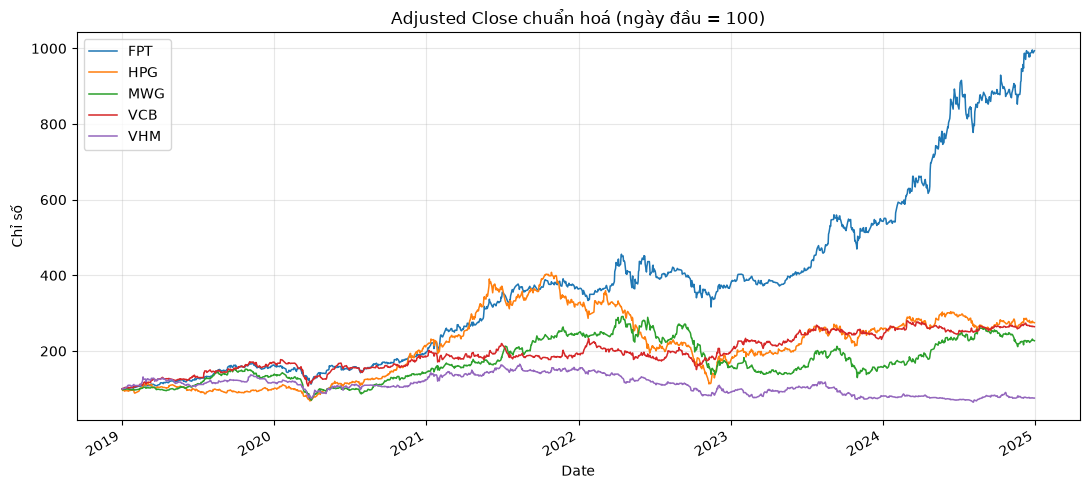


✔ Đã lưu kết quả vào: D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm\Output


In [10]:
# ===================== CHẠY PIPELINE =====================
REPORT.clear()
raw = load_all()
adj = step1_adjusted_prices(raw)
trading = step2_non_trading_days(adj)
aligned, panels, master, holidays = step3_calendar_alignment(trading)
final_checks(panels)
outliers = diagnose_outliers(aligned, panels)
save_outputs(aligned, panels, holidays)

In [11]:
print(outliers.to_string())
for tk in ["MWG", "VCB"]:
    miss = trading["FPT"].index.difference(trading[tk].index)
    print(f"\n{tk}: thiếu {len(miss)} ngày so với FPT")
    print(pd.DataFrame({t: trading[t]["Volume"].reindex(miss) for t in ["FPT", "HPG", "VHM"]}))

         Date Ticker   R_adj  R_close  R_prev  R_next  Factor_chg  Gap_days  Traded    Volume Near_event                          Nghi_van
0  2021-02-17    FPT  0.0926   0.0926  0.0000  0.0039        -0.0         9    True    724720                       thiếu phiên liền trước
1  2020-05-19    HPG  0.1211   0.1211 -0.0062 -0.0130        -0.0         5    True  57620082                       thiếu phiên liền trước
2  2021-07-09    HPG -0.0956  -0.0956 -0.0095 -0.0381        -0.0         7    True  88514471                       thiếu phiên liền trước
3  2021-07-09    MWG  0.1256   0.1256  0.0377 -0.0085        -0.0         7    True   3036600                       thiếu phiên liền trước
4  2021-09-09    MWG  0.0780   0.0780 -0.0063  0.0000         0.0         2    True   5089600             không rõ / có thể biến động thật
5  2019-07-17    VCB  0.0948   0.0948  0.0000  0.0026        -0.0        14    True   1209106                       thiếu phiên liền trước

MWG: thiếu 7 ngày so với F

Phần 2:  Tính Log Returns

In [12]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
# ===================== CẤU HÌNH (giống notebook Phần 1) =====================
def find_base_dir() -> Path:
    env = os.environ.get("PROJECT_DIR")
    if env:
        return Path(env)
    default = Path(r"D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm")
    if default.exists():
        return default
    cwd = Path.cwd()
    return cwd.parent if cwd.name.lower() == "code" else cwd


BASE_DIR = find_base_dir()
OUTPUT_DIR = next((BASE_DIR / n for n in ("Output", "Ouput") if (BASE_DIR / n).exists()),
                  BASE_DIR / "Output")
PRICE_FILE = OUTPUT_DIR / "panel_AdjClose.csv"
if not PRICE_FILE.exists():
    raise FileNotFoundError(f"Không thấy {PRICE_FILE}. Hãy chạy notebook Phần 1 trước.")
print("OUTPUT_DIR:", OUTPUT_DIR)

OUTPUT_DIR: D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm\Output


In [14]:
# ===================== 3.1 TÍNH LOG RETURNS =====================
def compute_log_returns(prices: pd.DataFrame) -> pd.DataFrame:
    """r_t = ln(P_t / P_{t-1}) với P = Adj Close. Bỏ dòng đầu tiên (không có P_{t-1})."""
    p = prices.sort_index().astype(float)
    if (p <= 0).any().any():
        raise ValueError("Có giá <= 0, không lấy log được – kiểm tra lại Phần 1.")
    r = np.log(p / p.shift(1)).iloc[1:]
    r.index.name = "Date"
    return r


prices = pd.read_csv(PRICE_FILE, index_col="Date", parse_dates=True)
log_ret = compute_log_returns(prices)

print(f"Kích thước: {log_ret.shape[0]} phiên x {log_ret.shape[1]} mã | "
      f"{log_ret.index.min().date()} -> {log_ret.index.max().date()} | NaN: {int(log_ret.isna().sum().sum())}")
display(log_ret.head())

Kích thước: 1452 phiên x 5 mã | 2019-01-03 -> 2024-12-30 | NaN: 0


,FPT,HPG,MWG,VCB,VHM
Date,,,,,
2019-01-03,-0.009756,-0.043124,-0.029676,0.000000,-0.004090
2019-01-04,0.007326,0.006757,0.007203,0.014815,0.010870
2019-01-07,0.016888,-0.011855,0.016608,0.003670,0.002699
2019-01-08,0.004773,-0.017182,-0.011835,0.007299,0.000000
2019-01-09,0.009479,0.022280,0.016529,0.014441,0.000000


In [15]:
# ===================== 3.2 THỐNG KÊ MÔ TẢ LOG RETURNS =====================
TRADING_DAYS = 252
stats = pd.DataFrame({
    "Số quan sát": log_ret.count(),
    "Trung bình ngày": log_ret.mean(),
    "Độ lệch chuẩn ngày": log_ret.std(),
    "Trung bình năm": log_ret.mean() * TRADING_DAYS,
    "Biến động năm": log_ret.std() * np.sqrt(TRADING_DAYS),
    "Min": log_ret.min(),
    "Max": log_ret.max(),
    "Skewness": log_ret.skew(),
    "Kurtosis (dư)": log_ret.kurt(),
    "Lợi suất tích luỹ": log_ret.sum(),   # tính cộng dồn của log-return
})
display(stats.round(5))

log_ret.to_csv(OUTPUT_DIR / "log_returns.csv", encoding="utf-8-sig")
stats.to_csv(OUTPUT_DIR / "log_returns_stats.csv", encoding="utf-8-sig")
print("✔ Đã lưu log_returns.csv và log_returns_stats.csv")

,Số quan sát,Trung bình ngày,Độ lệch chuẩn ngày,Trung bình năm,Biến động năm,Min,Max,Skewness,Kurtosis (dư),Lợi suất tích luỹ
FPT,1452,0.00158,0.01693,0.39855,0.26874,-0.07240,0.08853,0.00416,3.55141,2.29643
HPG,1452,0.00070,0.02182,0.17550,0.34638,-0.10049,0.11430,-0.04135,2.31868,1.01124
MWG,1452,0.00057,0.02188,0.14241,0.34739,-0.07253,0.11835,-0.21963,2.75439,0.82058
VCB,1452,0.00067,0.01634,0.16871,0.25931,-0.07248,0.09060,-0.03873,3.46807,0.97210
VHM,1452,-0.00019,0.01982,-0.04849,0.31466,-0.07257,0.06899,0.02347,2.78262,-0.27942


✔ Đã lưu log_returns.csv và log_returns_stats.csv


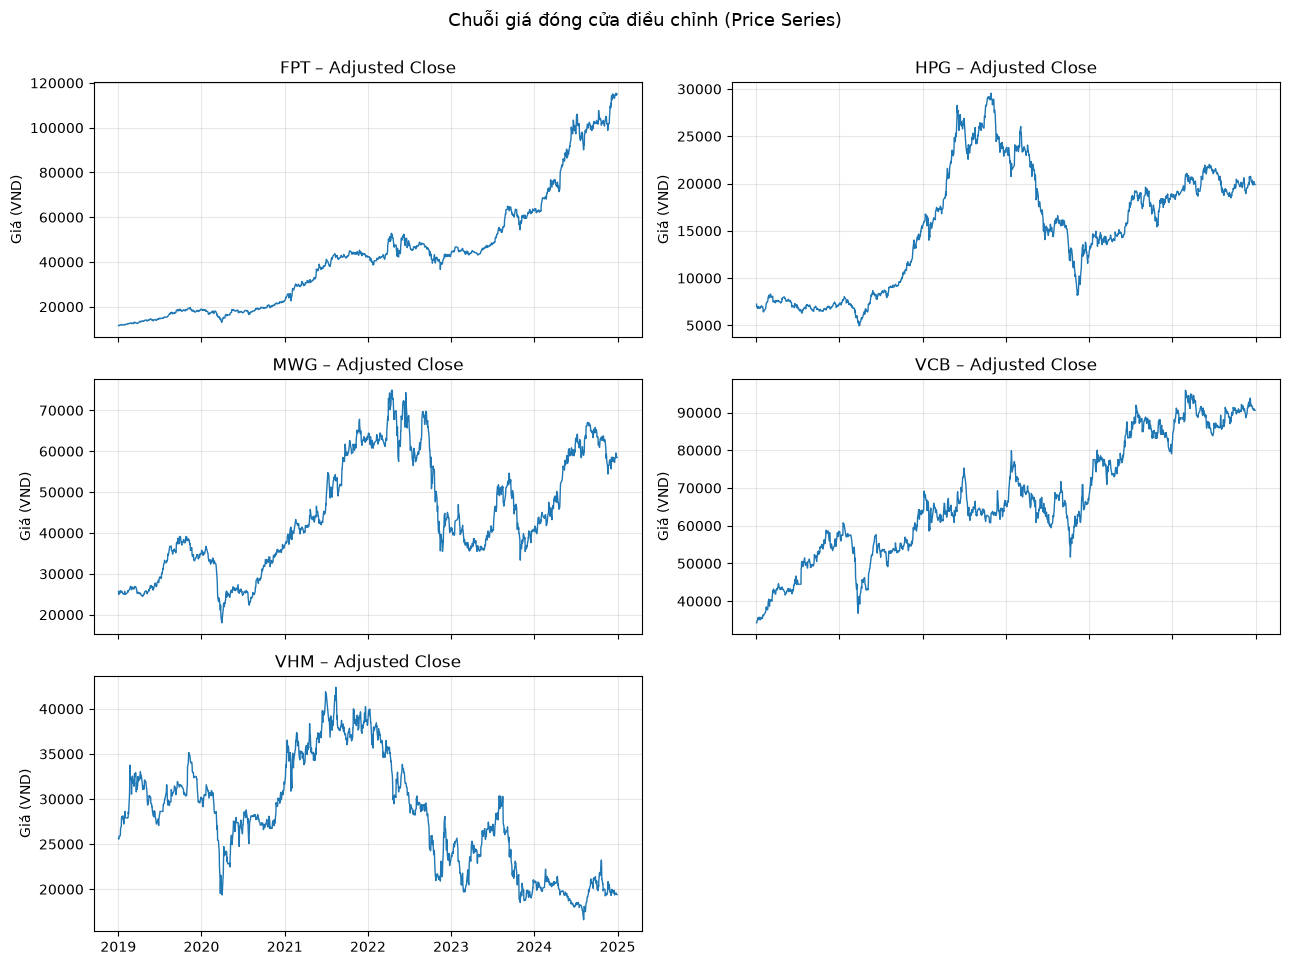

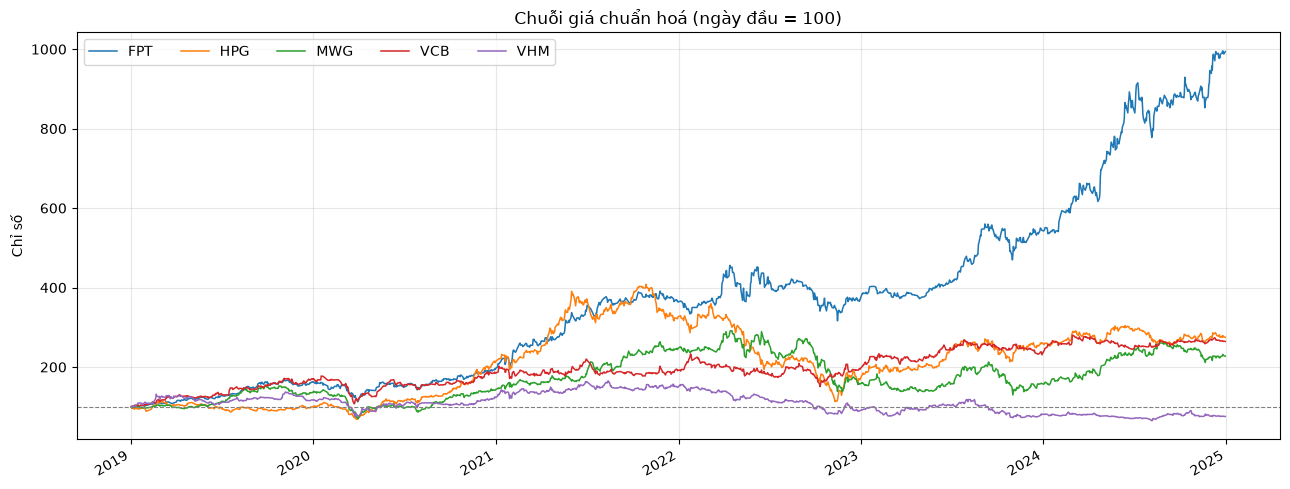

In [16]:
# ===================== 3.3 BIỂU ĐỒ CHUỖI GIÁ (PRICE SERIES) =====================
tickers = list(prices.columns)
n = len(tickers)
ncol = 2 if n > 1 else 1
nrow = int(np.ceil(n / ncol))

# (a) Giá Adj Close từng mã – mỗi mã một ô vì thang giá khác nhau
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.2 * nrow), sharex=True, squeeze=False)
for ax, tk in zip(axes.flat, tickers):
    ax.plot(prices.index, prices[tk], lw=1, color="tab:blue")
    ax.set_title(f"{tk} – Adjusted Close")
    ax.set_ylabel("Giá (VND)")
    ax.grid(alpha=0.3)
for ax in axes.flat[n:]:
    ax.set_visible(False)
fig.suptitle("Chuỗi giá đóng cửa điều chỉnh (Price Series)", fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "price_series.png", dpi=150, bbox_inches="tight")
plt.show()

# (b) Giá chuẩn hoá = 100 tại ngày đầu để so sánh các mã trên cùng một trục
norm = prices / prices.iloc[0] * 100
ax = norm.plot(figsize=(13, 5), lw=1.1)
ax.axhline(100, color="grey", ls="--", lw=0.8)
ax.set_title("Chuỗi giá chuẩn hoá (ngày đầu = 100)")
ax.set_ylabel("Chỉ số"); ax.set_xlabel("")
ax.grid(alpha=0.3); ax.legend(ncol=min(n, 5))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "price_series_normalized.png", dpi=150)

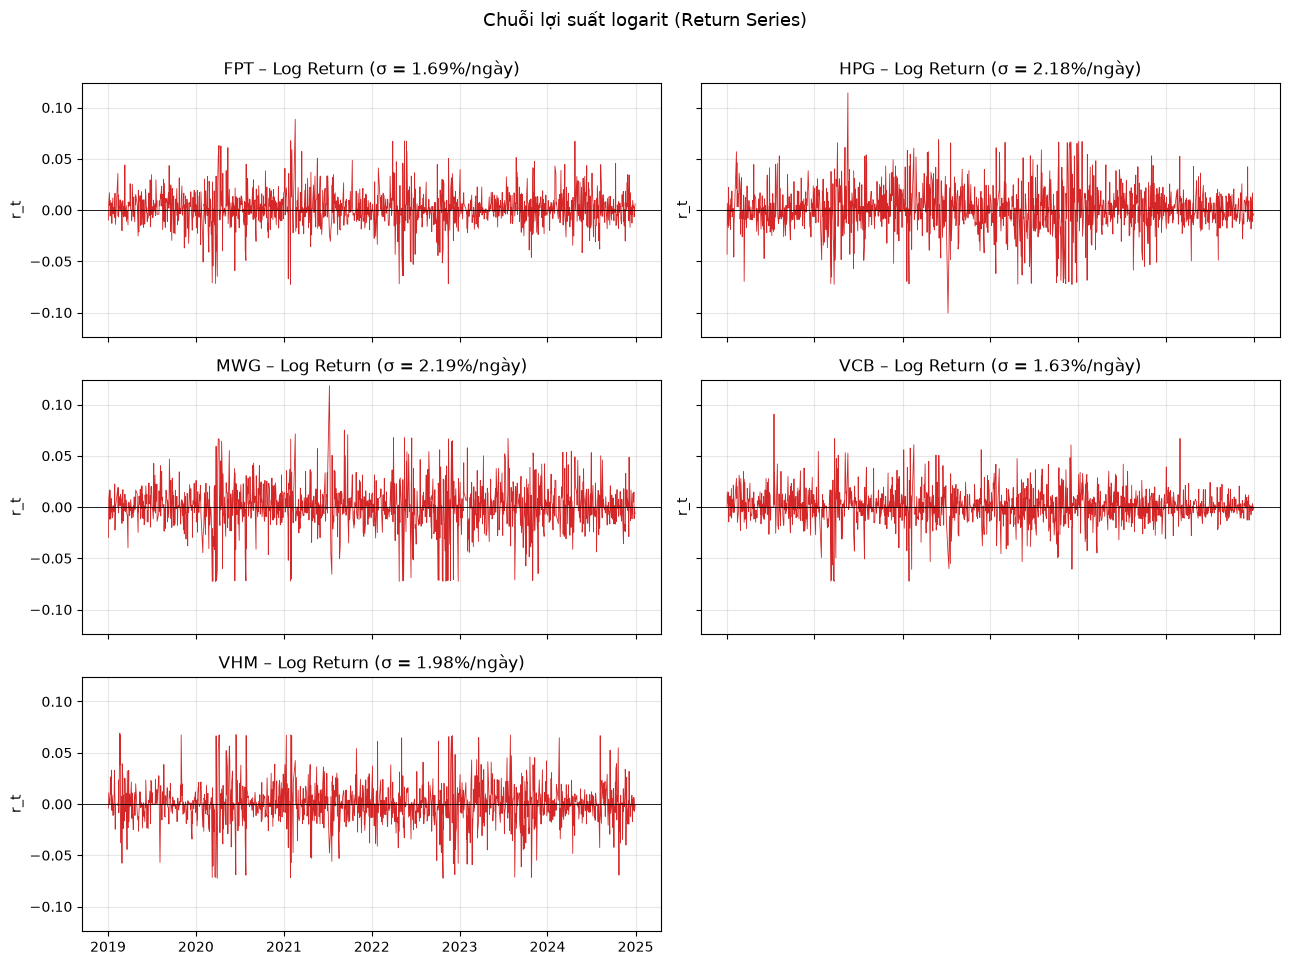

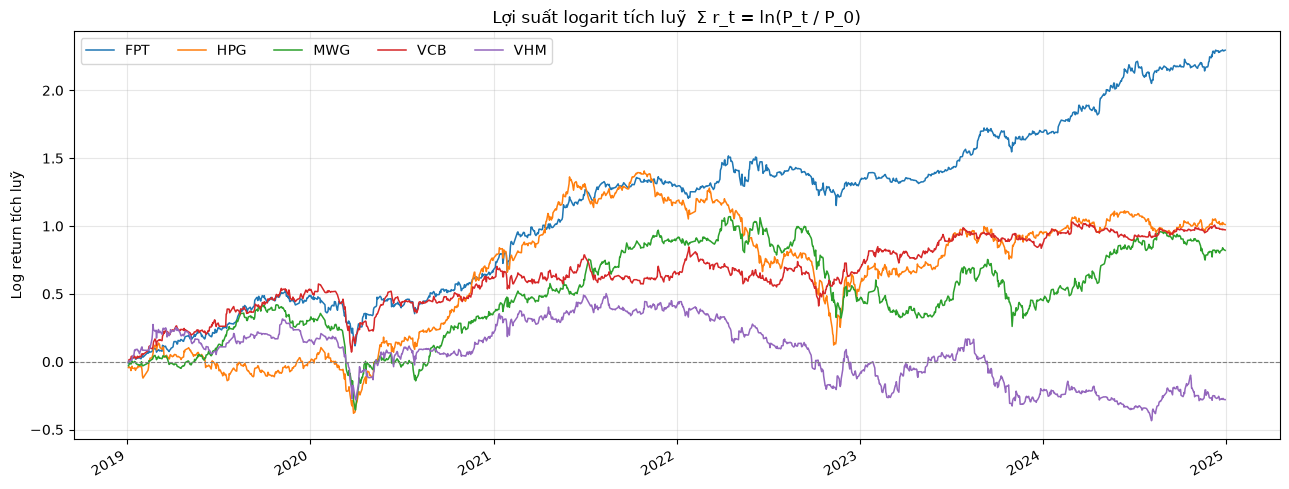

In [17]:
# ===================== 3.4 BIỂU ĐỒ CHUỖI LỢI SUẤT (RETURN SERIES) =====================
# (a) Log return theo thời gian – cùng trục tung để so sánh mức biến động giữa các mã
ylim = log_ret.abs().max().max() * 1.05
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.2 * nrow), sharex=True, sharey=True, squeeze=False)
for ax, tk in zip(axes.flat, tickers):
    ax.plot(log_ret.index, log_ret[tk], lw=0.6, color="tab:red")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_ylim(-ylim, ylim)
    ax.set_title(f"{tk} – Log Return (σ = {log_ret[tk].std():.2%}/ngày)")
    ax.set_ylabel("r_t")
    ax.grid(alpha=0.3)
for ax in axes.flat[n:]:
    ax.set_visible(False)
fig.suptitle("Chuỗi lợi suất logarit (Return Series)", fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "return_series.png", dpi=150, bbox_inches="tight")
plt.show()

# (b) Lợi suất log tích luỹ: sum(r_t) = ln(P_t / P_0)
cum = log_ret.cumsum()
ax = cum.plot(figsize=(13, 5), lw=1.1)
ax.axhline(0, color="grey", ls="--", lw=0.8)
ax.set_title("Lợi suất logarit tích luỹ  Σ r_t = ln(P_t / P_0)")
ax.set_ylabel("Log return tích luỹ"); ax.set_xlabel("")
ax.grid(alpha=0.3); ax.legend(ncol=min(n, 5))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cumulative_log_return.png", dpi=150)
plt.show()

In [18]:
# 4. Thống kê mô tả & Kiểm định 
# (Descriptive Statistics & Statistical Tests)
# cài hệ thống
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tools.sm_exceptions import InterpolationWarning

In [19]:
# ===================== CẤU HÌNH =====================
def find_base_dir() -> Path:
    env = os.environ.get("PROJECT_DIR")
    if env:
        return Path(env)
    default = Path(r"D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm")
    if default.exists():
        return default
    cwd = Path.cwd()
    return cwd.parent if cwd.name.lower() == "code" else cwd


BASE_DIR = find_base_dir()
OUTPUT_DIR = next((BASE_DIR / n for n in ("Output", "Ouput") if (BASE_DIR / n).exists()),
                  BASE_DIR / "Output")
FIG_DIR = OUTPUT_DIR / "part4_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05              # mức ý nghĩa
LB_LAGS = [5, 10, 20]     # số trễ cho Ljung-Box
ACF_LAGS = 30             # số trễ vẽ ACF
TRADING_DAYS = 252

In [20]:
# ===================== ĐỌC DỮ LIỆU =====================
price_file = OUTPUT_DIR / "panel_AdjClose.csv"
ret_file = OUTPUT_DIR / "log_returns.csv"
if not price_file.exists():
    raise FileNotFoundError(f"Không thấy {price_file}. Hãy chạy notebook Phần 1 trước.")

prices = pd.read_csv(price_file, index_col="Date", parse_dates=True).sort_index()
if ret_file.exists():
    log_ret = pd.read_csv(ret_file, index_col="Date", parse_dates=True).sort_index()
else:                                   # chưa chạy Phần 3 -> tự tính r_t = ln(P_t / P_{t-1})
    log_ret = np.log(prices / prices.shift(1)).iloc[1:]
    print("⚠ Không thấy log_returns.csv, đã tự tính log return từ panel_AdjClose.csv")

tickers = list(log_ret.columns)
n_tk = len(tickers)
print(f"Giá     : {prices.shape[0]} phiên x {prices.shape[1]} mã")
print(f"Lợi suất: {log_ret.shape[0]} phiên x {log_ret.shape[1]} mã | "
      f"{log_ret.index.min().date()} -> {log_ret.index.max().date()}")
print("Các mã  :", ", ".join(tickers))


def grid(n, ncol=2, h=3.2, w=13, **kw):
    """Tạo lưới ô vẽ cho n mã, ẩn các ô thừa."""
    ncol = min(ncol, n)
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(w, h * nrow), squeeze=False, **kw)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat

Giá     : 1453 phiên x 5 mã
Lợi suất: 1452 phiên x 5 mã | 2019-01-03 -> 2024-12-30
Các mã  : FPT, HPG, MWG, VCB, VHM


In [21]:
# ===================== 4a. THỐNG KÊ MÔ TẢ =====================
def describe_returns(r: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for tk in r.columns:
        x = r[tk].dropna().values
        S = stats.skew(x, bias=True)                    # dùng moment mẫu (đúng như công thức JB)
        K = stats.kurtosis(x, fisher=False, bias=True)  # kurtosis thường (chuẩn = 3)
        rows[tk] = {
            "N": len(x),
            "Mean": x.mean(),
            "Std": x.std(ddof=1),
            "Skewness": S,
            "Kurtosis": K,
            "Excess Kurtosis": K - 3,
            "Min": x.min(),
            "Median": np.median(x),
            "Max": x.max(),
            "Mean năm": x.mean() * TRADING_DAYS,
            "Std năm": x.std(ddof=1) * np.sqrt(TRADING_DAYS),
        }
    return pd.DataFrame(rows).T


desc = describe_returns(log_ret)
desc["N"] = desc["N"].astype(int)
display(desc.style.format({c: "{:.5f}" for c in desc.columns if c != "N"}))

for tk, row in desc.iterrows():
    lech = "lệch trái (đuôi trái dài)" if row["Skewness"] < 0 else "lệch phải (đuôi phải dài)"
    nhon = "đuôi dày, nhọn hơn chuẩn" if row["Kurtosis"] > 3 else "đuôi mỏng hơn chuẩn"
    print(f"{tk}: S = {row['Skewness']:+.3f} -> {lech}; K = {row['Kurtosis']:.3f} -> {nhon}")

,N,Mean,Std,Skewness,Kurtosis,Excess Kurtosis,Min,Median,Max,Mean năm,Std năm
FPT,1452,0.00158,0.01693,0.00416,6.53506,3.53506,-0.07240,0.00107,0.08853,0.39855,0.26874
HPG,1452,0.00070,0.02182,-0.04130,5.30658,2.30658,-0.10049,0.00000,0.11430,0.17550,0.34638
MWG,1452,0.00057,0.02188,-0.21940,5.74078,2.74078,-0.07253,0.00000,0.11835,0.14241,0.34739
VCB,1452,0.00067,0.01634,-0.03869,6.45201,3.45201,-0.07248,0.00000,0.09060,0.16871,0.25931
VHM,1452,-0.00019,0.01982,0.02345,5.76892,2.76892,-0.07257,0.00000,0.06899,-0.04849,0.31466


FPT: S = +0.004 -> lệch phải (đuôi phải dài); K = 6.535 -> đuôi dày, nhọn hơn chuẩn
HPG: S = -0.041 -> lệch trái (đuôi trái dài); K = 5.307 -> đuôi dày, nhọn hơn chuẩn
MWG: S = -0.219 -> lệch trái (đuôi trái dài); K = 5.741 -> đuôi dày, nhọn hơn chuẩn
VCB: S = -0.039 -> lệch trái (đuôi trái dài); K = 6.452 -> đuôi dày, nhọn hơn chuẩn
VHM: S = +0.023 -> lệch phải (đuôi phải dài); K = 5.769 -> đuôi dày, nhọn hơn chuẩn


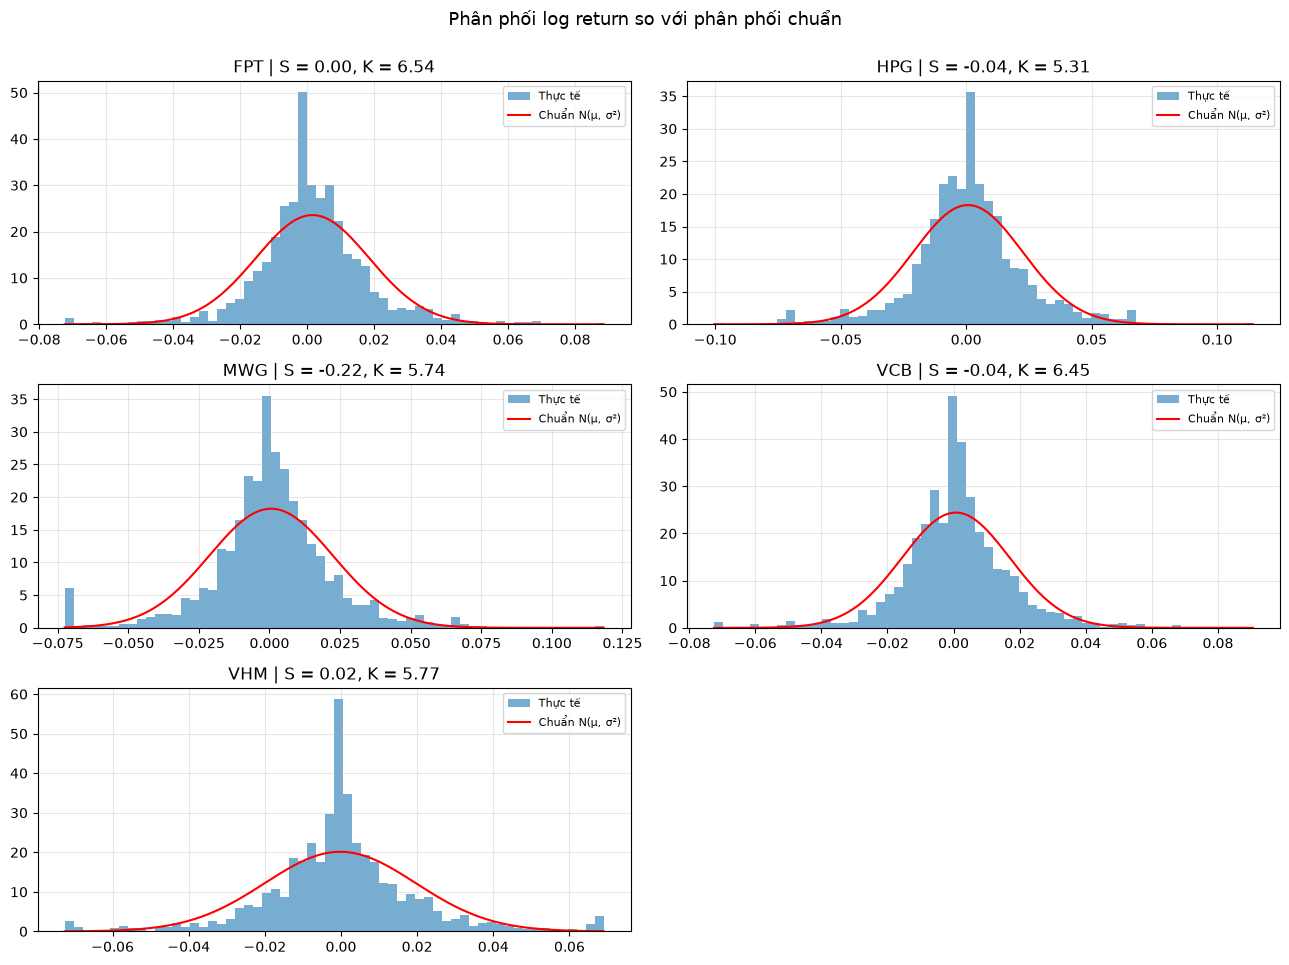

In [22]:
# Histogram lợi suất so với phân phối chuẩn cùng mean & std
fig, axes = grid(n_tk)
for ax, tk in zip(axes, tickers):
    x = log_ret[tk].dropna()
    ax.hist(x, bins=60, density=True, alpha=0.6, color="tab:blue", label="Thực tế")
    xs = np.linspace(x.min(), x.max(), 400)
    ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "r-", lw=1.5, label="Chuẩn N(μ, σ²)")
    ax.set_title(f"{tk} | S = {desc.loc[tk, 'Skewness']:.2f}, K = {desc.loc[tk, 'Kurtosis']:.2f}")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("Phân phối log return so với phân phối chuẩn", fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "4a_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# ===================== 4b. KIỂM ĐỊNH JARQUE-BERA =====================
def jarque_bera(x):
    """Tính JB theo đúng công thức; đối chiếu với scipy.stats.jarque_bera."""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)
    S = stats.skew(x, bias=True)
    K = stats.kurtosis(x, fisher=False, bias=True)
    jb = n / 6 * (S ** 2 + (K - 3) ** 2 / 4)
    p = stats.chi2.sf(jb, df=2)
    return n, S, K, jb, p


crit = stats.chi2.ppf(1 - ALPHA, df=2)
rows = {}
for tk in tickers:
    n, S, K, jb, p = jarque_bera(log_ret[tk])
    jb_scipy = stats.jarque_bera(log_ret[tk].dropna()).statistic
    rows[tk] = {"n": n, "Skewness": S, "Kurtosis": K, "JB": jb,
                "JB (scipy)": jb_scipy, f"Giá trị tới hạn χ²(2)": crit, "p-value": p,
                "Kết luận": "Bác bỏ H0 – KHÔNG chuẩn" if p < ALPHA else "Chưa bác bỏ H0 – chuẩn"}
jb_table = pd.DataFrame(rows).T
display(jb_table)

,n,Skewness,Kurtosis,JB,JB (scipy),Giá trị tới hạn χ²(2),p-value,Kết luận
FPT,1452,0.004155,6.535062,756.052166,756.052166,5.991465,0.0,Bác bỏ H0 – KHÔNG chuẩn
HPG,1452,-0.041302,5.306578,322.291206,322.291206,5.991465,0.0,Bác bỏ H0 – KHÔNG chuẩn
MWG,1452,-0.2194,5.740783,466.118474,466.118474,5.991465,0.0,Bác bỏ H0 – KHÔNG chuẩn
VCB,1452,-0.038691,6.452015,721.30479,721.30479,5.991465,0.0,Bác bỏ H0 – KHÔNG chuẩn
VHM,1452,0.023448,5.768919,463.981282,463.981282,5.991465,0.0,Bác bỏ H0 – KHÔNG chuẩn


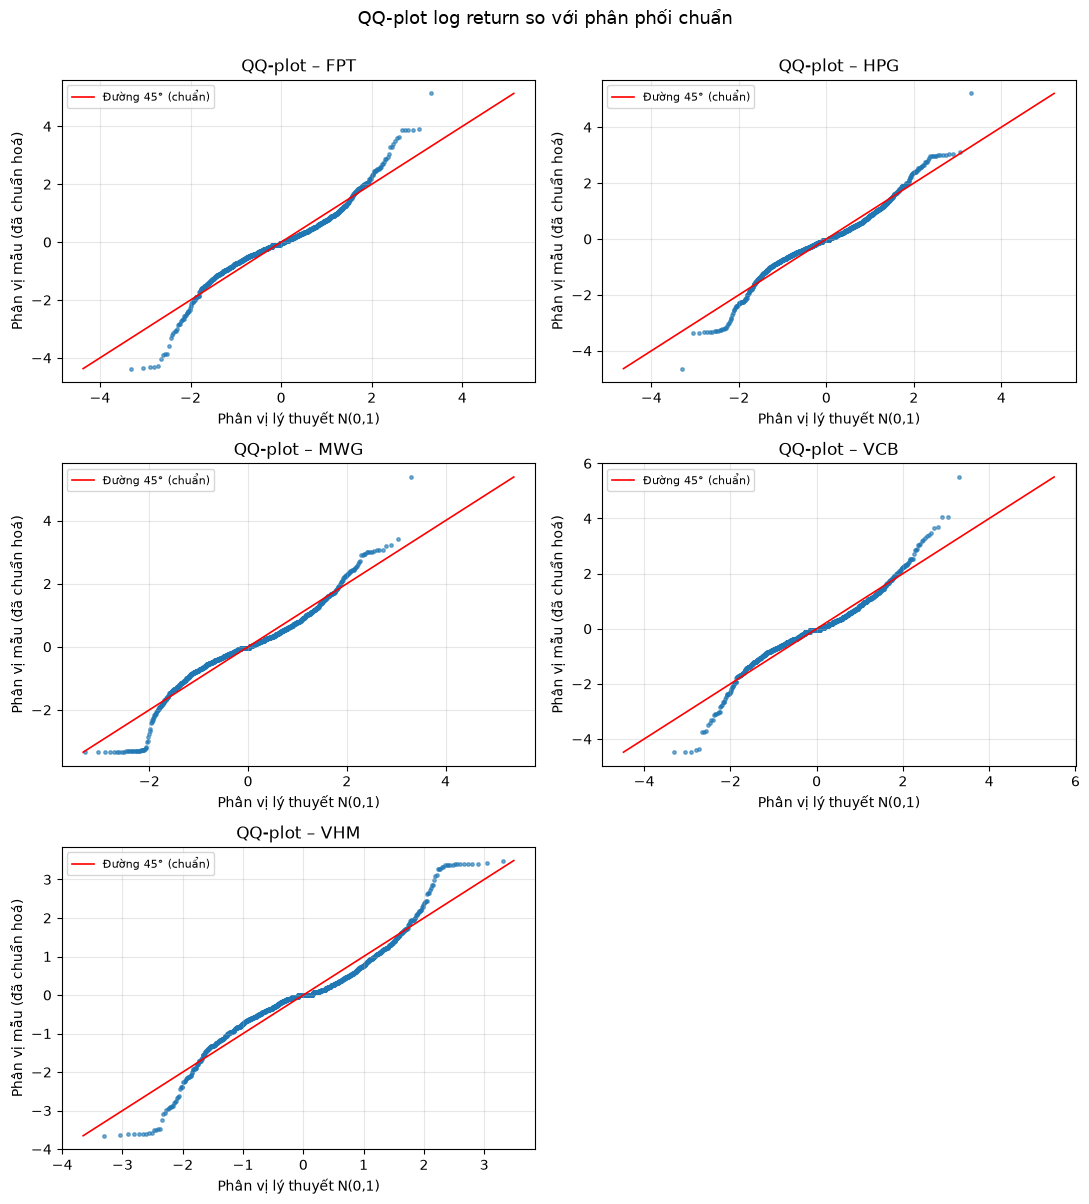

In [24]:
# QQ-plot: lợi suất chuẩn hoá so với phân vị của N(0,1)
fig, axes = grid(n_tk, h=4, w=11)
for ax, tk in zip(axes, tickers):
    x = log_ret[tk].dropna()
    z = (x - x.mean()) / x.std()
    (osm, osr), _ = stats.probplot(z, dist="norm")
    ax.scatter(osm, osr, s=6, alpha=0.6, color="tab:blue")
    lim = [min(osm.min(), osr.min()), max(osm.max(), osr.max())]
    ax.plot(lim, lim, "r-", lw=1.2, label="Đường 45° (chuẩn)")
    ax.set_title(f"QQ-plot – {tk}")
    ax.set_xlabel("Phân vị lý thuyết N(0,1)")
    ax.set_ylabel("Phân vị mẫu (đã chuẩn hoá)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("QQ-plot log return so với phân phối chuẩn", fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "4b_qqplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# ===================== 4c. KIỂM ĐỊNH ADF & KPSS =====================
def adf_test(x):
    x = pd.Series(x).dropna()
    stat, p, lag, nobs, cv, _ = adfuller(x, regression="c", autolag="AIC")
    return {"ADF stat": stat, "ADF p-value": p, "ADF lag": lag, "ADF CV 5%": cv["5%"]}


def kpss_test(x):
    x = pd.Series(x).dropna()
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", InterpolationWarning)
        stat, p, lag, cv = kpss(x, regression="c", nlags="auto")
    # statsmodels chỉ tra bảng p trong [0.01, 0.10]; ngoài khoảng này p bị chặn ở biên
    note = ""
    if any(issubclass(i.category, InterpolationWarning) for i in w):
        note = "<0.01" if p <= 0.01 else ">0.10"
    return {"KPSS stat": stat, "KPSS p-value": p, "KPSS p (ghi chú)": note,
            "KPSS lag": lag, "KPSS CV 5%": cv["5%"]}


def conclude(p_adf, p_kpss):
    adf_rej, kpss_rej = p_adf < ALPHA, p_kpss < ALPHA
    if adf_rej and not kpss_rej:
        return "DỪNG"
    if not adf_rej and kpss_rej:
        return "KHÔNG DỪNG"
    if adf_rej and kpss_rej:
        return "Mâu thuẫn (có thể dừng quanh xu hướng / có điểm gãy)"
    return "Mâu thuẫn (dữ liệu chưa đủ thông tin)"


series_sets = {
    "Giá (Adj Close)": prices,
    "Log return": log_ret,
}
rows = []
for name, df in series_sets.items():
    for tk in tickers:
        res = {"Chuỗi": name, "Mã": tk, **adf_test(df[tk]), **kpss_test(df[tk])}
        res["Kết luận"] = conclude(res["ADF p-value"], res["KPSS p-value"])
        rows.append(res)
stationarity = pd.DataFrame(rows).set_index(["Chuỗi", "Mã"])
display(stationarity.style.format(
    {c: "{:.4f}" for c in stationarity.columns
     if stationarity[c].dtype.kind == "f"}))

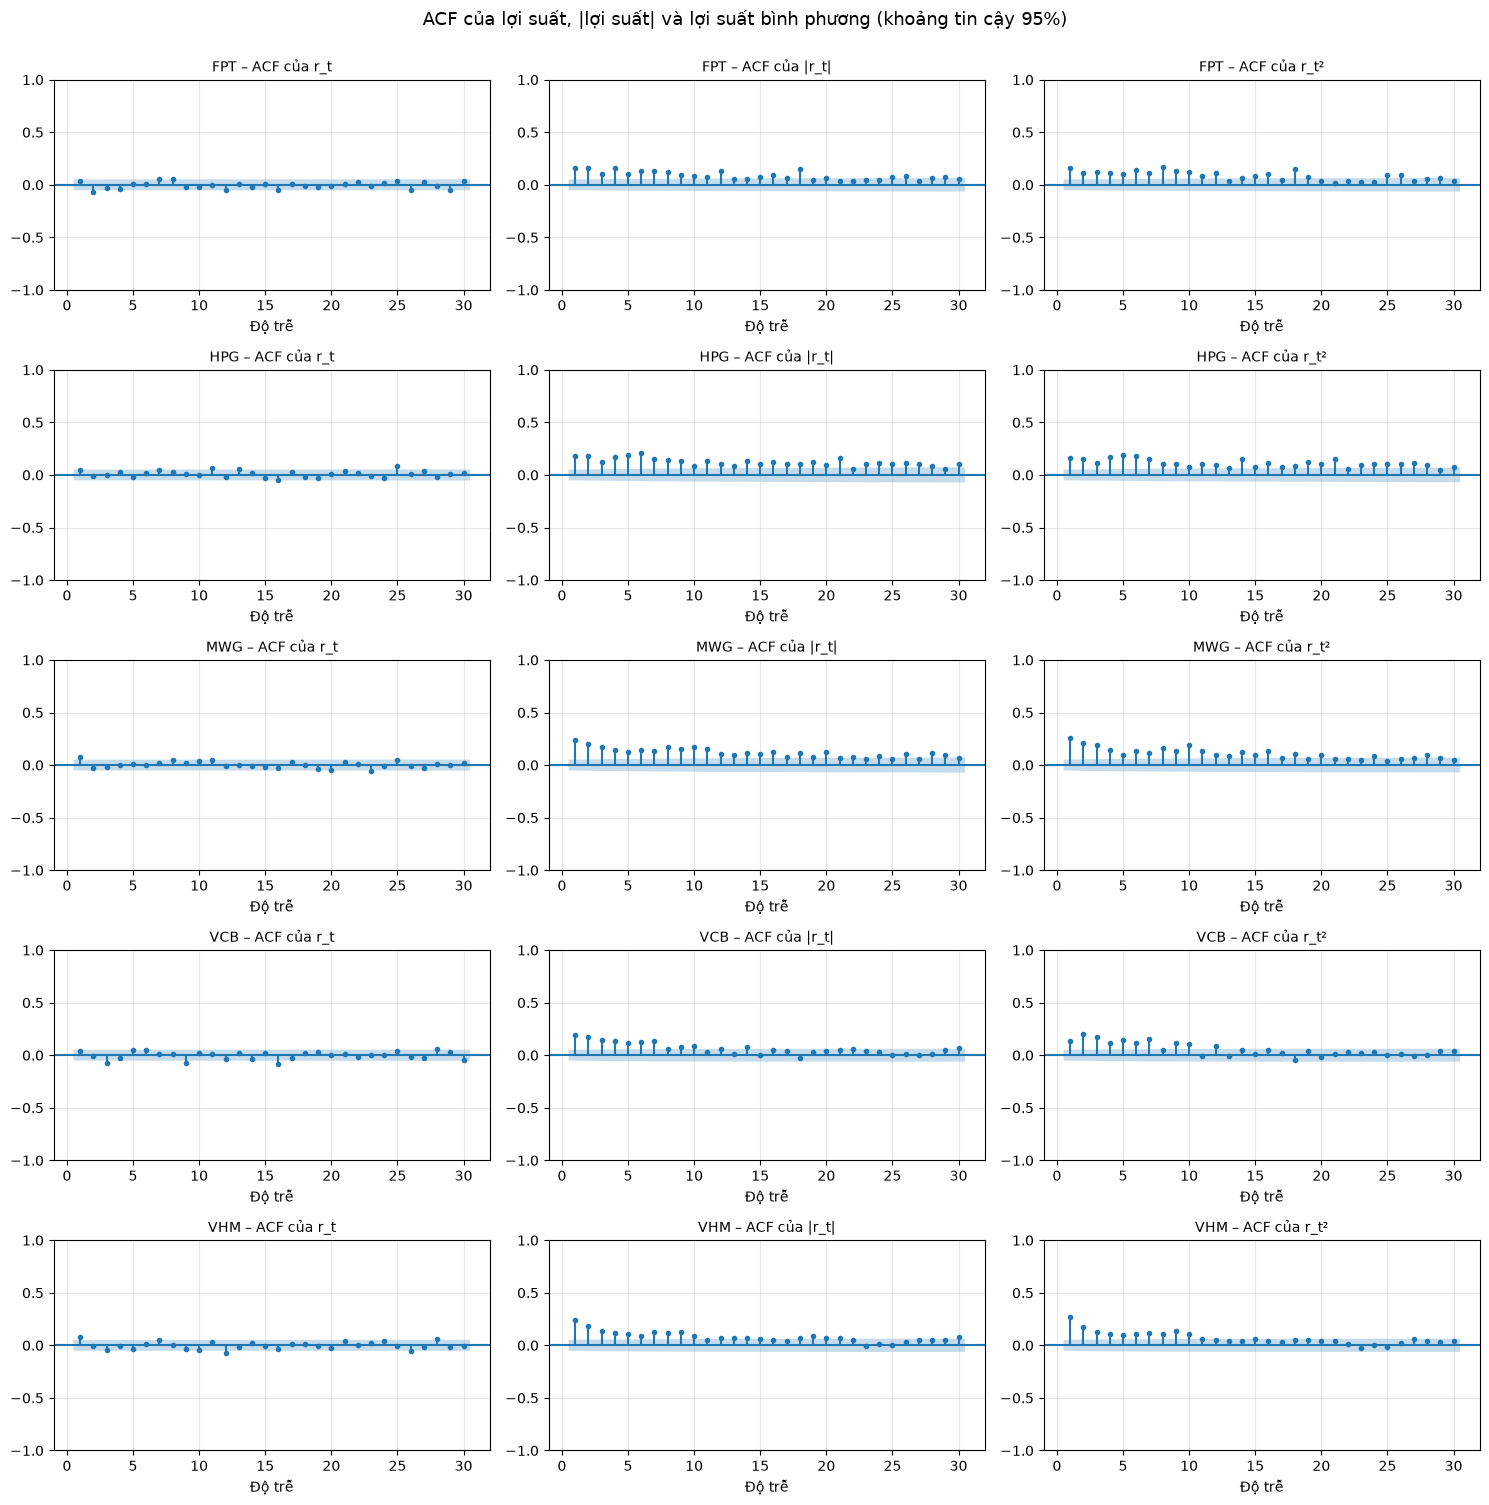

In [26]:
# ===================== 4d. BIỂU ĐỒ ACF =====================
transforms = {
    "r_t": lambda s: s,
    "|r_t|": lambda s: s.abs(),
    "r_t²": lambda s: s ** 2,
}

fig, axes = plt.subplots(n_tk, 3, figsize=(15, 3 * n_tk), squeeze=False)
for i, tk in enumerate(tickers):
    x = log_ret[tk].dropna()
    for j, (name, f) in enumerate(transforms.items()):
        ax = axes[i, j]
        plot_acf(f(x), lags=ACF_LAGS, zero=False, alpha=ALPHA, ax=ax, markersize=3)
        ax.set_title(f"{tk} – ACF của {name}", fontsize=10)
        ax.set_xlabel("Độ trễ")
        ax.grid(alpha=0.3)
fig.suptitle(f"ACF của lợi suất, |lợi suất| và lợi suất bình phương (khoảng tin cậy {1 - ALPHA:.0%})",
             fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "4d_acf.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# ===================== 4d. KIỂM ĐỊNH LJUNG-BOX =====================
rows = []
for tk in tickers:
    x = log_ret[tk].dropna()
    for name, f in transforms.items():
        lb = acorr_ljungbox(f(x), lags=LB_LAGS, return_df=True)
        for lag, r in lb.iterrows():
            rows.append({"Mã": tk, "Chuỗi": name, "Lag": int(lag),
                         "Q-stat": r["lb_stat"], "p-value": r["lb_pvalue"],
                         "Kết luận": "Có tự tương quan" if r["lb_pvalue"] < ALPHA
                                     else "Không có tự tương quan"})
ljungbox = pd.DataFrame(rows)

# Bảng gọn: p-value theo (Mã, Chuỗi) x Lag
lb_pivot = ljungbox.pivot_table(index=["Mã", "Chuỗi"], columns="Lag", values="p-value",
                                sort=False)
lb_pivot.columns = [f"p (lag {c})" for c in lb_pivot.columns]
sty = lb_pivot.style.format("{:.4f}")
sty_map = getattr(sty, "map", None) or sty.applymap      # pandas < 2.1 dùng applymap
display(sty_map(lambda v: "background-color: #f8d7da" if v < ALPHA else ""))
print(f"Ô tô đỏ: p < {ALPHA} -> bác bỏ H0, có tự tương quan.")

Ô tô đỏ: p < 0.05 -> bác bỏ H0, có tự tương quan.


In [29]:
# ===================== TỔNG HỢP & LƯU KẾT QUẢ =====================
max_lag = max(LB_LAGS)
summary = pd.DataFrame(index=tickers)
summary["Skewness"] = desc["Skewness"]
summary["Kurtosis"] = desc["Kurtosis"]
summary["JB p-value"] = jb_table["p-value"].astype(float)
summary["Phân phối chuẩn?"] = np.where(summary["JB p-value"] < ALPHA, "Không", "Có")
summary["Giá"] = stationarity.xs("Giá (Adj Close)", level="Chuỗi")["Kết luận"]
summary["Lợi suất"] = stationarity.xs("Log return", level="Chuỗi")["Kết luận"]
for name in transforms:
    p = ljungbox[(ljungbox["Chuỗi"] == name) & (ljungbox["Lag"] == max_lag)].set_index("Mã")["p-value"]
    summary[f"LB p {name} (lag {max_lag})"] = p
display(summary.round(4))

with pd.ExcelWriter(OUTPUT_DIR / "part4_statistical_tests.xlsx", engine="openpyxl") as xw:
    summary.to_excel(xw, sheet_name="Tong_hop")
    desc.to_excel(xw, sheet_name="4a_Thong_ke_mo_ta")
    jb_table.to_excel(xw, sheet_name="4b_Jarque_Bera")
    stationarity.to_excel(xw, sheet_name="4c_ADF_KPSS")
    ljungbox.to_excel(xw, sheet_name="4d_Ljung_Box", index=False)
print(f"✔ Đã lưu bảng kết quả: {OUTPUT_DIR / 'part4_statistical_tests.xlsx'}")
print(f"✔ Đã lưu biểu đồ vào : {FIG_DIR}")

,Skewness,Kurtosis,JB p-value,Phân phối chuẩn?,Giá,Lợi suất,LB p r_t (lag 20),LB p |r_t| (lag 20),LB p r_t² (lag 20)
FPT,0.0042,6.5351,0.0,Không,KHÔNG DỪNG,DỪNG,0.0776,0.0,0.0
HPG,-0.0413,5.3066,0.0,Không,KHÔNG DỪNG,DỪNG,0.0588,0.0,0.0
MWG,-0.2194,5.7408,0.0,Không,KHÔNG DỪNG,DỪNG,0.0711,0.0,0.0
VCB,-0.0387,6.4520,0.0,Không,KHÔNG DỪNG,DỪNG,0.0008,0.0,0.0
VHM,0.0234,5.7689,0.0,Không,KHÔNG DỪNG,DỪNG,0.0255,0.0,0.0


✔ Đã lưu bảng kết quả: D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm\Output\part4_statistical_tests.xlsx
✔ Đã lưu biểu đồ vào : D:\Năm 3\Ứng dụng công nghệ trong TCNH\Project midterm\Output\part4_figures
